# M2 — Exploratory Data Analysis and Data Cleaning

Weather data for Grenoble, Chamrousse and Voiron (2024–2026).

Source: Open-Meteo Historical Weather API.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the raw weather dataset
df = pd.read_parquet("weather_data.parquet")

# Display the first five rows
display(df.head())

# Check the dataset dimensions
print("Dataset shape:", df.shape)

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,snow_depth,location
0,2024-10-01T00:00,16.1,82,0.0,5.4,0.0,Grenoble
1,2024-10-01T01:00,15.8,85,0.0,4.9,0.0,Grenoble
2,2024-10-01T02:00,15.8,84,0.0,4.7,0.0,Grenoble
3,2024-10-01T03:00,15.7,86,0.0,5.0,0.0,Grenoble
4,2024-10-01T04:00,15.7,86,0.0,4.9,0.0,Grenoble


Dataset shape: (52560, 7)


In [2]:
# Display column names
print("Columns:", df.columns.tolist())

# Display column types and non-null counts
df.info()

# Display descriptive statistics
display(df.describe())

Columns: ['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m', 'snow_depth', 'location']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52560 entries, 0 to 52559
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   time                  52560 non-null  object 
 1   temperature_2m        52560 non-null  float64
 2   relative_humidity_2m  52560 non-null  int64  
 3   precipitation         52560 non-null  float64
 4   wind_speed_10m        52560 non-null  float64
 5   snow_depth            52560 non-null  float64
 6   location              52560 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 2.8+ MB


,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,snow_depth
count,52560.000000,52560.000000,52560.000000,52560.000000,52560.000000
mean,10.904429,73.037272,0.153838,4.630896,0.116408
std,9.505837,19.793460,0.606619,3.504937,0.297132
min,-15.000000,6.000000,0.000000,0.000000,0.000000
25%,3.700000,59.000000,0.000000,2.200000,0.000000
50%,10.300000,77.000000,0.000000,3.700000,0.000000
75%,17.600000,90.000000,0.000000,6.100000,0.020000
max,38.700000,100.000000,15.700000,31.100000,1.610000


In [3]:
# Convert the time column to datetime
df["time"] = pd.to_datetime(df["time"])

# Check the date range
print("Start date:", df["time"].min())
print("End date:", df["time"].max())

# Check missing values
print("\nMissing values:")
print(df.isna().sum())

# Check duplicated observations for the same location and time
print("\nDuplicate observations:")
print(df.duplicated(subset=["location", "time"]).sum())

# Check the number of observations per location
print("\nObservations per location:")
print(df["location"].value_counts())

Start date: 2024-10-01 00:00:00
End date: 2026-09-30 23:00:00

Missing values:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
snow_depth              0
location                0
dtype: int64

Duplicate observations:
0

Observations per location:
location
Grenoble      17520
Chamrousse    17520
Voiron        17520
Name: count, dtype: int64


In [4]:
# Check hourly continuity for each location
for location, group in df.groupby("location"):
    times = group["time"].sort_values()

    # Compute the difference between consecutive timestamps
    time_differences = times.diff().dropna()

    # Count intervals that are not exactly one hour
    irregular_intervals = (time_differences != pd.Timedelta(hours=1)).sum()

    print(f"{location}: {irregular_intervals} irregular intervals")

Chamrousse: 0 irregular intervals
Grenoble: 0 irregular intervals
Voiron: 0 irregular intervals


C:\Users\omarf\AppData\Local\Temp\ipykernel_8396\3241352608.py:9: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  irregular_intervals = (time_differences != pd.Timedelta(hours=1)).sum()


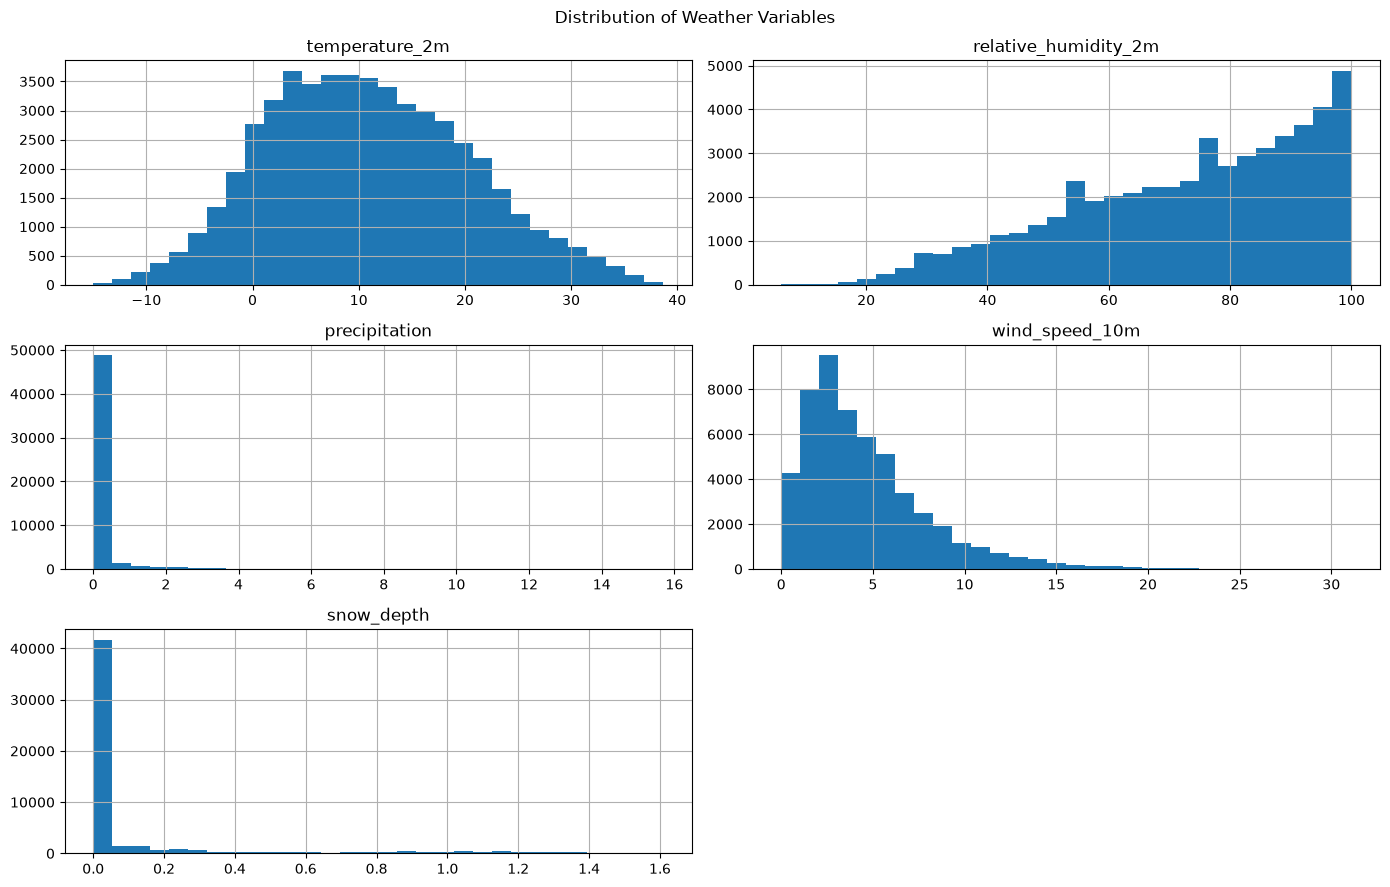

In [5]:
# Select the numerical weather variables
weather_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "snow_depth"
]

# Plot histograms for all weather variables
df[weather_columns].hist(bins=30, figsize=(14, 9))

plt.suptitle("Distribution of Weather Variables")
plt.tight_layout()
plt.show()

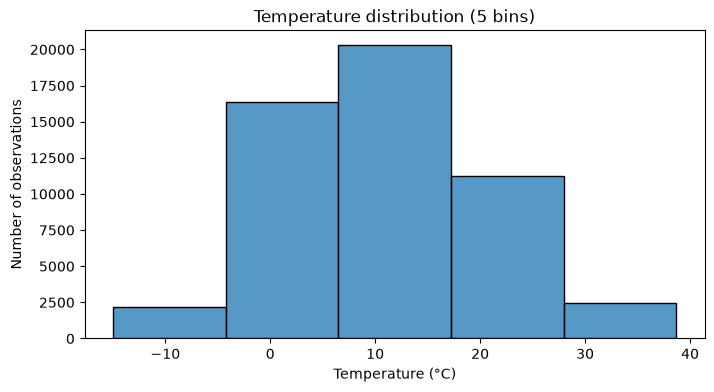

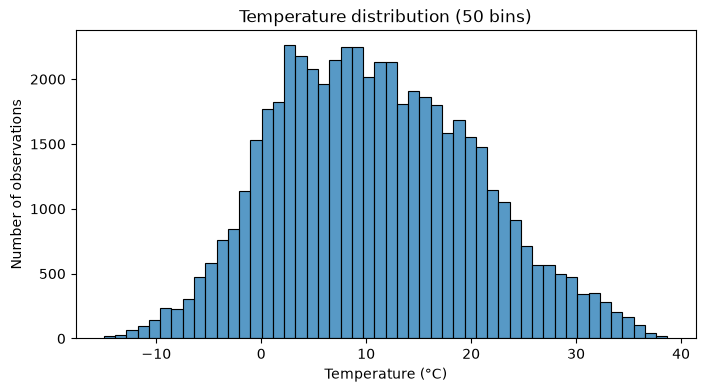

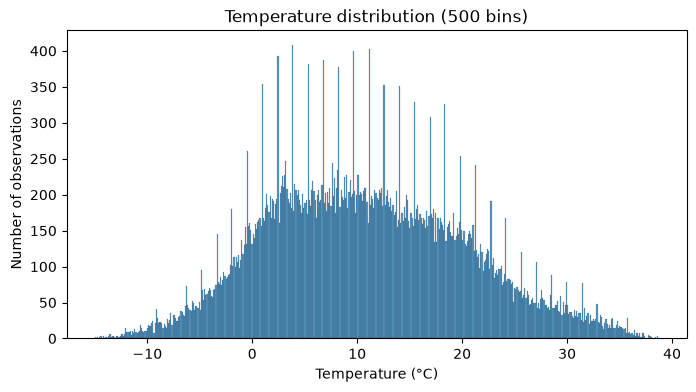

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

for bins in [5, 50, 500]:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x="temperature_2m",
        bins=bins
    )

    plt.title(f"Temperature distribution ({bins} bins)")
    plt.xlabel("Temperature (°C)")
    plt.ylabel("Number of observations")
    plt.show()

### Effect of the number of bins

We compared temperature histograms using 5, 50, and 500 bins.

- 5 bins: shows the general distribution.
- 50 bins: provides a more detailed view.
- 500 bins: shows very fine variations but makes the graph harder to interpret.

We selected 50 bins as a reasonable balance between detail and readability.

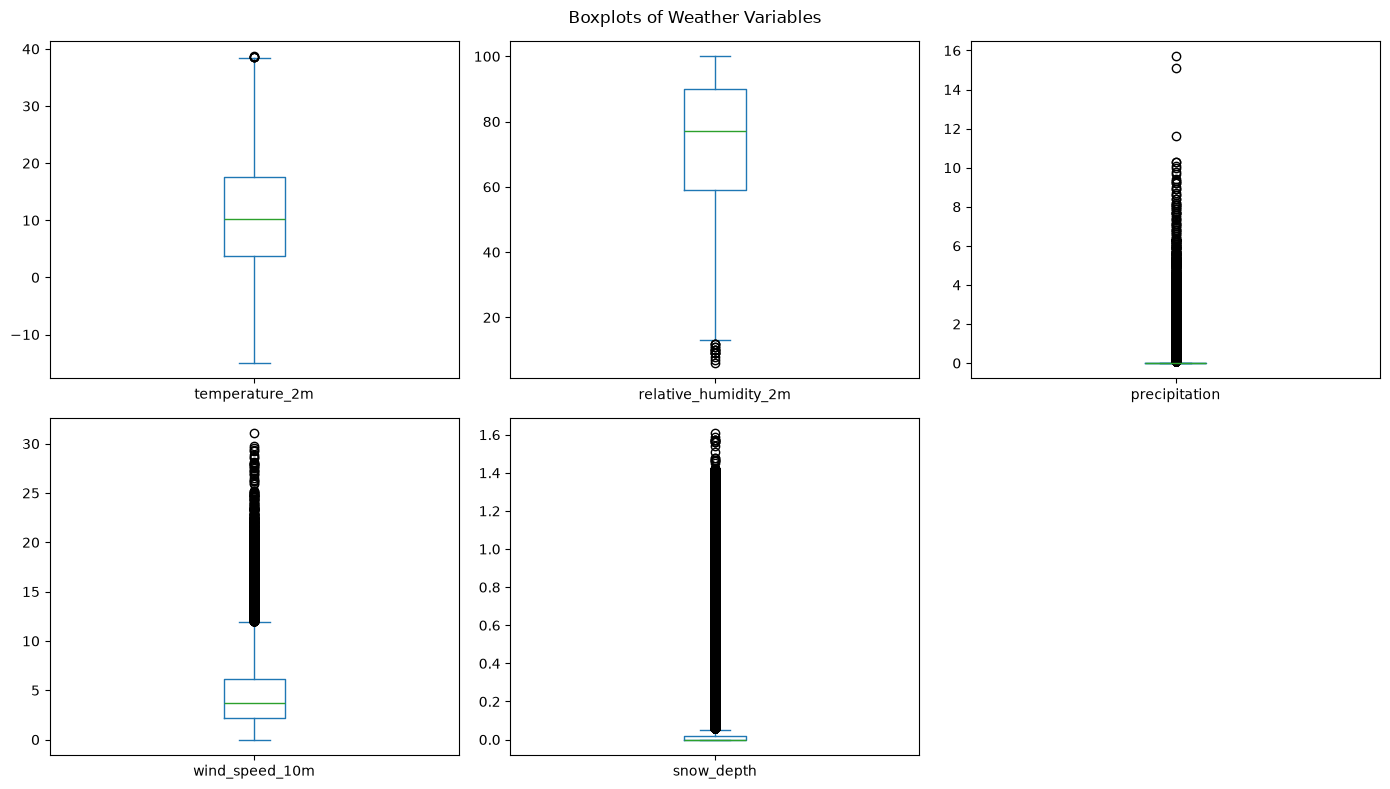

In [6]:
# Plot boxplots to identify potential outliers
df[weather_columns].plot(
    kind="box",
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    sharey=False
)

plt.suptitle("Boxplots of Weather Variables")
plt.tight_layout()
plt.show()

In [7]:
# Check physically invalid weather values
invalid_values = {
    "relative_humidity_2m": (
        (df["relative_humidity_2m"] < 0) |
        (df["relative_humidity_2m"] > 100)
    ).sum(),

    "precipitation": (df["precipitation"] < 0).sum(),

    "wind_speed_10m": (df["wind_speed_10m"] < 0).sum(),

    "snow_depth": (df["snow_depth"] < 0).sum()
}

# Display the number of invalid values
for variable, count in invalid_values.items():
    print(f"{variable}: {count} invalid values")

relative_humidity_2m: 0 invalid values
precipitation: 0 invalid values
wind_speed_10m: 0 invalid values
snow_depth: 0 invalid values


In [8]:
# Compute average weather values for each location
location_summary = df.groupby("location")[weather_columns].mean()

# Display the summary table
display(location_summary.round(2))

,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,snow_depth
location,,,,,
Chamrousse,5.62,70.16,0.17,3.81,0.31
Grenoble,14.21,72.66,0.17,3.98,0.04
Voiron,12.88,76.30,0.12,6.10,0.00


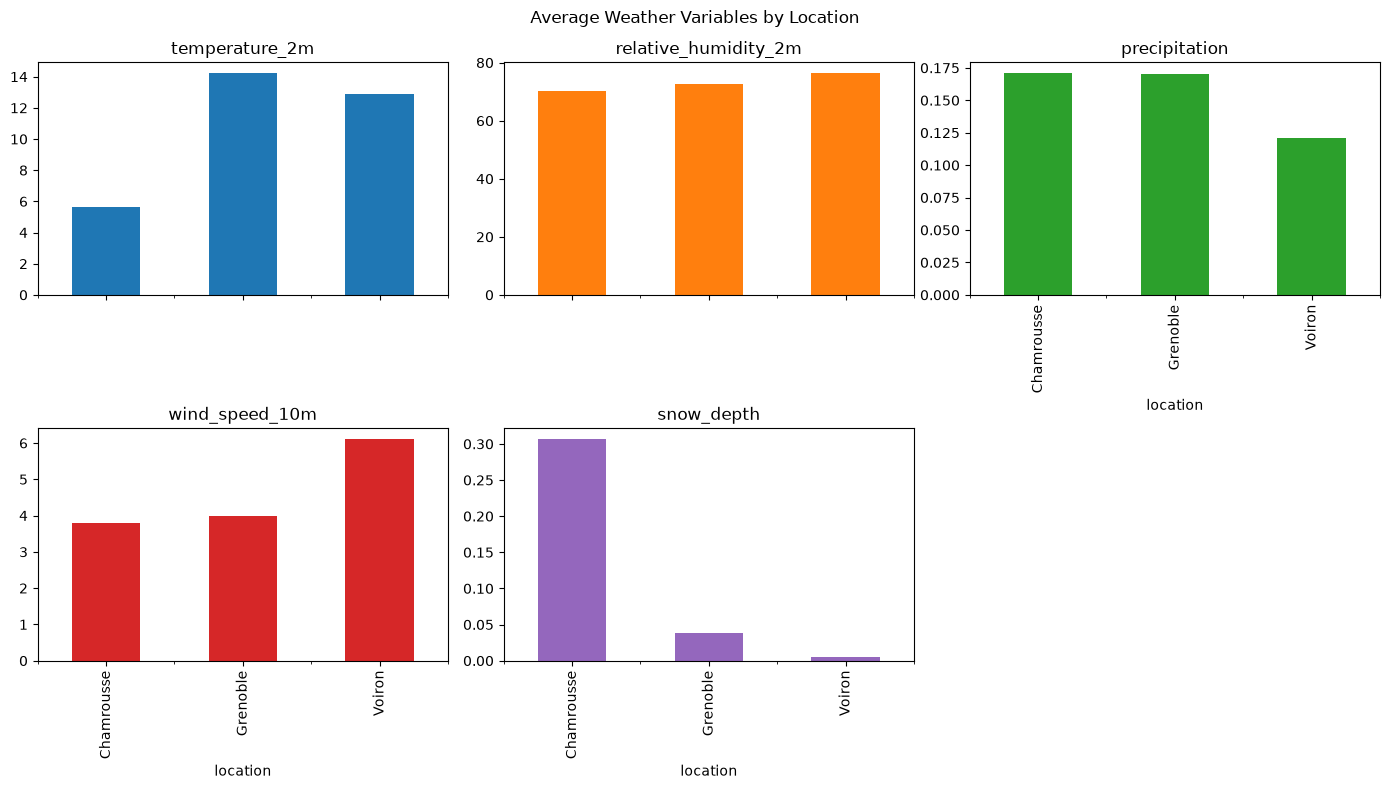

In [9]:
# Plot average weather variables by location
location_summary.plot(
    kind="bar",
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    legend=False,
    sharey=False
)

plt.suptitle("Average Weather Variables by Location")
plt.tight_layout()
plt.show()

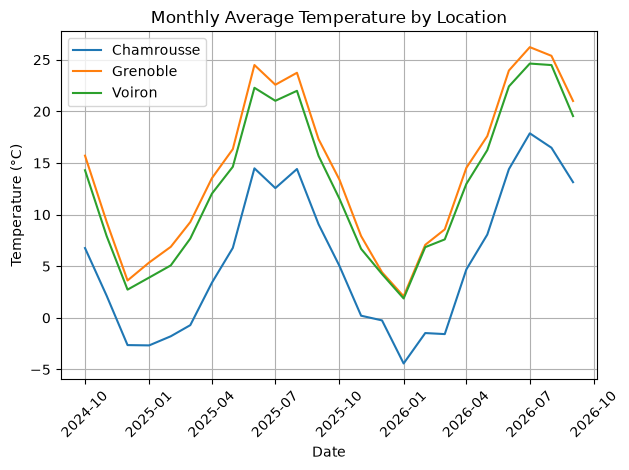

In [10]:
# Compute monthly average temperature for each location
monthly_temperature = (
    df.groupby([
        "location",
        pd.Grouper(key="time", freq="MS")
    ])["temperature_2m"]
    .mean()
    .reset_index()
)

# Plot monthly temperature evolution
for location, group in monthly_temperature.groupby("location"):
    plt.plot(
        group["time"],
        group["temperature_2m"],
        label=location
    )

plt.title("Monthly Average Temperature by Location")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

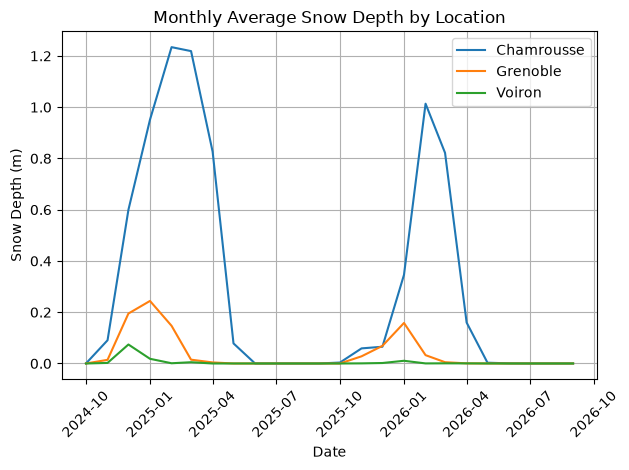

In [11]:
# Compute monthly average snow depth for each location
monthly_snow = (
    df.groupby([
        "location",
        pd.Grouper(key="time", freq="MS")
    ])["snow_depth"]
    .mean()
    .reset_index()
)

# Plot monthly snow depth evolution
for location, group in monthly_snow.groupby("location"):
    plt.plot(
        group["time"],
        group["snow_depth"],
        label=location
    )

plt.title("Monthly Average Snow Depth by Location")
plt.xlabel("Date")
plt.ylabel("Snow Depth (m)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
# Create a separate cleaned dataset
df_clean = df.copy()

# Ensure correct datetime format
df_clean["time"] = pd.to_datetime(df_clean["time"])

# Sort observations chronologically
df_clean = df_clean.sort_values(
    ["location", "time"]
).reset_index(drop=True)

# Save the cleaned dataset locally
df_clean.to_parquet(
    "weather_data_clean.parquet",
    index=False
)

# Verify the final dataset
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))
print("Cleaned dataset saved successfully.")

Original shape: (52560, 7)
Cleaned shape: (52560, 7)
Rows removed: 0
Cleaned dataset saved successfully.


## EDA Findings and Cleaning Decisions

The dataset contains 52,560 hourly weather observations from three locations (Grenoble, Chamrousse and Voiron), covering October 2024 to September 2026.

**Data quality:** No missing values, duplicate location-time pairs, irregular hourly intervals or physically invalid humidity, precipitation, wind speed and snow depth values were detected.

**Distributions:** Temperature follows a roughly bell-shaped distribution, while precipitation and snow depth contain many zero values. High precipitation and snow values were retained because they may represent genuine weather events rather than data errors.

**Geographical differences:** Chamrousse has the lowest average temperature (5.62°C) and the highest average snow depth (0.31 m). Grenoble is warmer on average (14.21°C), while Voiron has the highest average wind speed (6.10 km/h).

**Temporal patterns:** Temperature shows a clear seasonal cycle, with higher values in summer and lower values in winter. Snow depth is concentrated in winter, especially in Chamrousse.

**Cleaning decisions:** The time column was converted to datetime and the observations were sorted by location and time. No rows were removed.

**Limitations:** The dataset represents three coordinate-based historical weather estimates from Open-Meteo, not direct measurements from three physical weather stations. The findings should not be generalized to the entire Grenoble region without further validation.
